# Notebook 03: Chuỗi 10.000 Sự kiện Hàng nhập (Phase 3 Event Generator)

**Nghiên cứu:** Tái hiện bài báo *Agentic Architecture for Progressive Autonomous Storage Location Assignment in Warehouses* (Rodrigo Furlan de Assis et al., 2026).

Notebook này trực quan hóa toàn diện kết quả **Giai đoạn 3**:
1. Chuỗi 10.000 sự kiện hàng nhập chính thức (`data/processed/inbound_events.csv`).
2. Kiểm tra độ khớp giữa xác suất lý thuyết (tần suất tồn kho) và tần suất thực nghiệm của 208 SKU.
3. Phân phối kích cỡ có điều kiện $s_t \in [4.0, 16.0]$ theo từng SKU.
4. Phân phối khối lượng lô hàng nhập (Batch size proxy) từ `Customer_Order.csv`.
5. Diễn biến lưu lượng hàng nhập (Inbound units volume) qua 10.000 sự kiện.
6. So sánh chuỗi chính với chuỗi độ nhạy S2 (Demand proxy).


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

sys.path.append('..')
from src.data.event_generator import validate_inbound_stream

print("Phase 3 environment loaded successfully.")


Phase 3 environment loaded successfully.


## 1. Tóm tắt Chuỗi Sự kiện Chính & Độ nhạy

In [2]:
df_summary = pd.read_csv('../outputs/tables/event_stream_summary.csv')
display(df_summary)

df_events = pd.read_csv('../data/processed/inbound_events.csv')
print(f"Tổng số sự kiện chính: {len(df_events):,}")
print(f"Số SKU xuất hiện: {df_events['reference'].nunique()}")
print(f"Dải kích cỡ: [{df_events['size'].min()}, {df_events['size'].max()}]")
print(f"Dải khối lượng lô (quantity): [{df_events['quantity'].min()}, {df_events['quantity'].max()}]")
print(f"Tổng số đơn vị hàng nhập tích lũy: {df_events['quantity'].sum():,} units")
display(df_events.head(8))


,Stream_Name,Seed,Total_Events,Unique_SKUs,Size_Min,Size_Max,Quantity_Min,Quantity_Max,Quantity_Mean,Quantity_Median,Total_Inbound_Units,Validation_Status
0,Primary Stream (Stock Frequency),42,10000,208,4.0,16.0,1,24,1.8546,1.0,18546,PASSED (100% catalog/size valid)
1,Sensitivity S2 (Demand Proxy),42,10000,182,4.0,16.0,1,24,1.8546,1.0,18546,PASSED (100% catalog/size valid)


Tổng số sự kiện chính: 10,000
Số SKU xuất hiện: 208
Dải kích cỡ: [4.0, 16.0]
Dải khối lượng lô (quantity): [1, 24]
Tổng số đơn vị hàng nhập tích lũy: 18,546 units


,event_id,reference,size,quantity,seed
0,1,2OAVPY,4.0,1,42
1,2,RUUOCB,4.0,1,42
2,3,ODZZLY,14.0,2,42
3,4,2T1DJM,4.0,1,42
4,5,F7LULH,7.0,1,42
5,6,UCRNWD,12.0,1,42
6,7,O7TSVL,13.0,1,42
7,8,Q50W5L,10.0,1,42


## 2. Phân phối Khối lượng Lô hàng Nhập (Batch Size Distribution)

,Quantity,Event_Count,Percentage
0,1,6798,67.98
1,2,1745,17.45
2,3,453,4.53
3,4,227,2.27
4,5,401,4.01
5,6,130,1.30
6,7,29,0.29
7,8,34,0.34
8,9,28,0.28
9,10,19,0.19


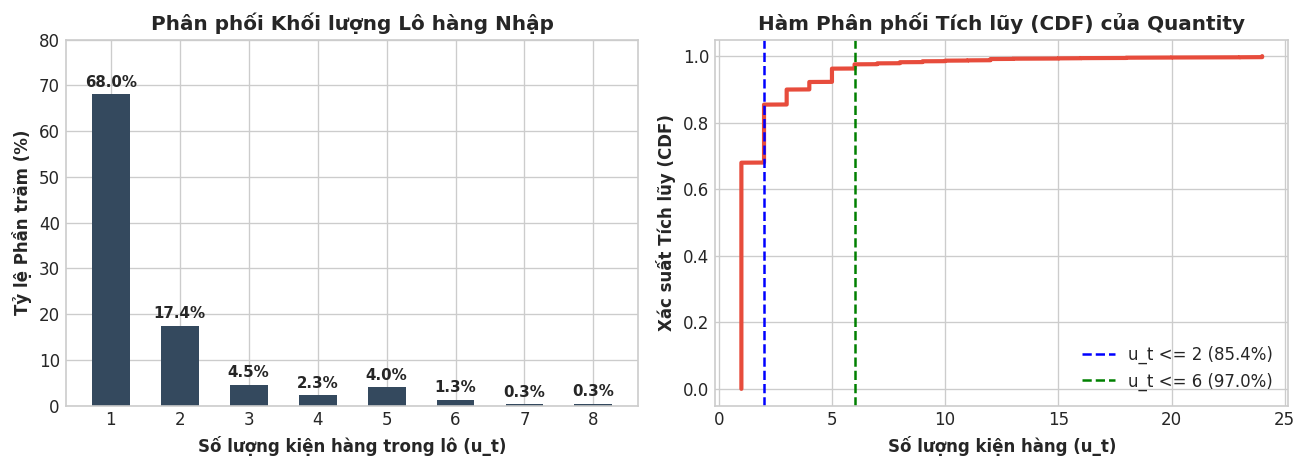

In [3]:
qty_dist = pd.read_csv('../outputs/tables/event_stream_quantity_distribution.csv')
display(qty_dist.head(10))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

top_qtys = qty_dist.head(8)
bars = ax1.bar([str(int(q)) for q in top_qtys['Quantity']], top_qtys['Percentage'], color='#34495E', width=0.55)
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=9)

ax1.set_xlabel('Số lượng kiện hàng trong lô (u_t)', fontweight='bold')
ax1.set_ylabel('Tỷ lệ Phần trăm (%)', fontweight='bold')
ax1.set_title('Phân phối Khối lượng Lô hàng Nhập', fontweight='bold')
ax1.set_ylim(0, 80)

sorted_qtys = np.sort(df_events['quantity'])
cum_prob = np.arange(1, len(sorted_qtys) + 1) / len(sorted_qtys)
ax2.plot(sorted_qtys, cum_prob, color='#E74C3C', linewidth=2.5)
ax2.axvline(2, color='blue', linestyle='--', label='u_t <= 2 (85.4%)')
ax2.axvline(6, color='green', linestyle='--', label='u_t <= 6 (97.0%)')
ax2.set_xlabel('Số lượng kiện hàng (u_t)', fontweight='bold')
ax2.set_ylabel('Xác suất Tích lũy (CDF)', fontweight='bold')
ax2.set_title('Hàm Phân phối Tích lũy (CDF) của Quantity', fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()


## 3. Độ khớp Tần suất SKU: Xác suất Lý thuyết vs Thực nghiệm

,Reference,Snapshot_Stock_Count,Theoretical_Probability,Sampled_Event_Count,Sampled_Frequency
0,AHR20O,75,0.0069,76,0.0076
1,PZUF7K,71,0.0066,56,0.0056
2,RAUDQ6,71,0.0066,55,0.0055
3,IYV9SV,70,0.0065,76,0.0076
4,UU4A1K,70,0.0065,64,0.0064
5,C5O9C9,66,0.0061,66,0.0066
6,B24J86,65,0.0060,68,0.0068
7,NJVZEL,65,0.0060,61,0.0061
8,56TC1Z,64,0.0059,61,0.0061
9,CVU3QV,63,0.0058,62,0.0062


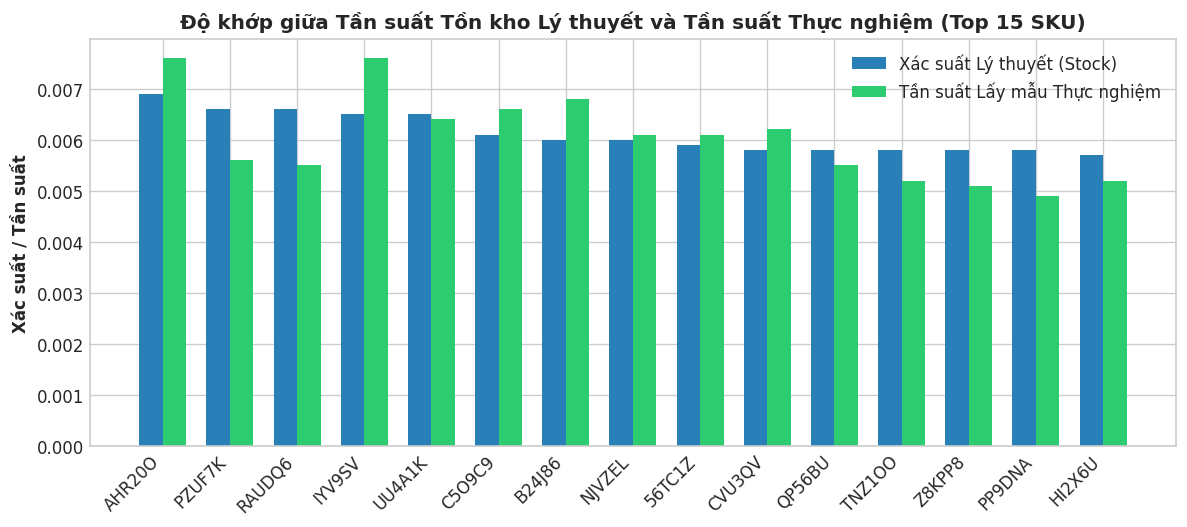

In [4]:
top_skus = pd.read_csv('../outputs/tables/event_stream_top_skus.csv')
display(top_skus.head(10))

plt.figure(figsize=(10, 4.5))
x = np.arange(len(top_skus[:15]))
width = 0.35

plt.bar(x - width/2, top_skus['Theoretical_Probability'][:15], width, label='Xác suất Lý thuyết (Stock)', color='#2980B9')
plt.bar(x + width/2, top_skus['Sampled_Frequency'][:15], width, label='Tần suất Lấy mẫu Thực nghiệm', color='#2ECC71')

plt.xticks(x, top_skus['Reference'][:15], rotation=45, ha='right')
plt.ylabel('Xác suất / Tần suất', fontweight='bold')
plt.title('Độ khớp giữa Tần suất Tồn kho Lý thuyết và Tần suất Thực nghiệm (Top 15 SKU)', fontweight='bold', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()


## 4. Phân phối Kích cỡ Hàng nhập ($s_t$) qua 10.000 Sự kiện

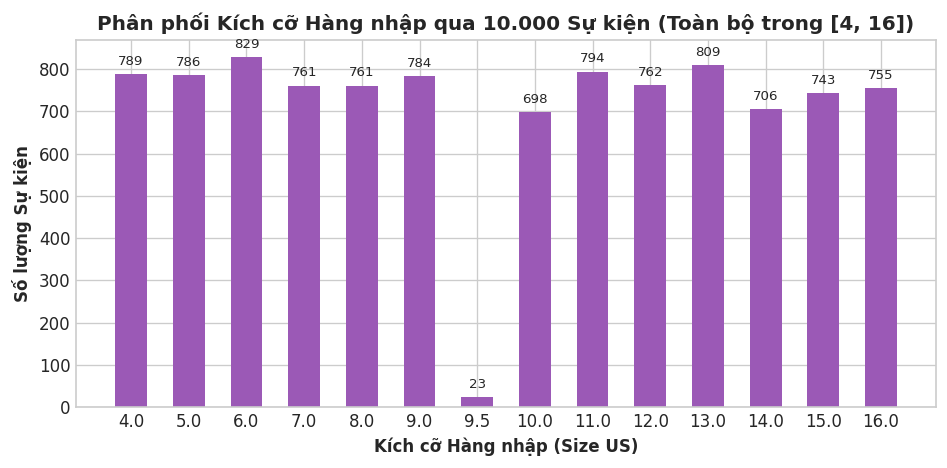

In [5]:
size_counts = df_events['size'].value_counts().sort_index()

plt.figure(figsize=(8, 4))
bars = plt.bar([str(s) for s in size_counts.index], size_counts.values, color='#9B59B6', width=0.55)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f'{int(yval)}', ha='center', va='bottom', fontsize=8)

plt.xlabel('Kích cỡ Hàng nhập (Size US)', fontweight='bold')
plt.ylabel('Số lượng Sự kiện', fontweight='bold')
plt.title('Phân phối Kích cỡ Hàng nhập qua 10.000 Sự kiện (Toàn bộ trong [4, 16])', fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Lưu lượng Hàng nhập Tích lũy & Cửa sổ 100 Sự kiện

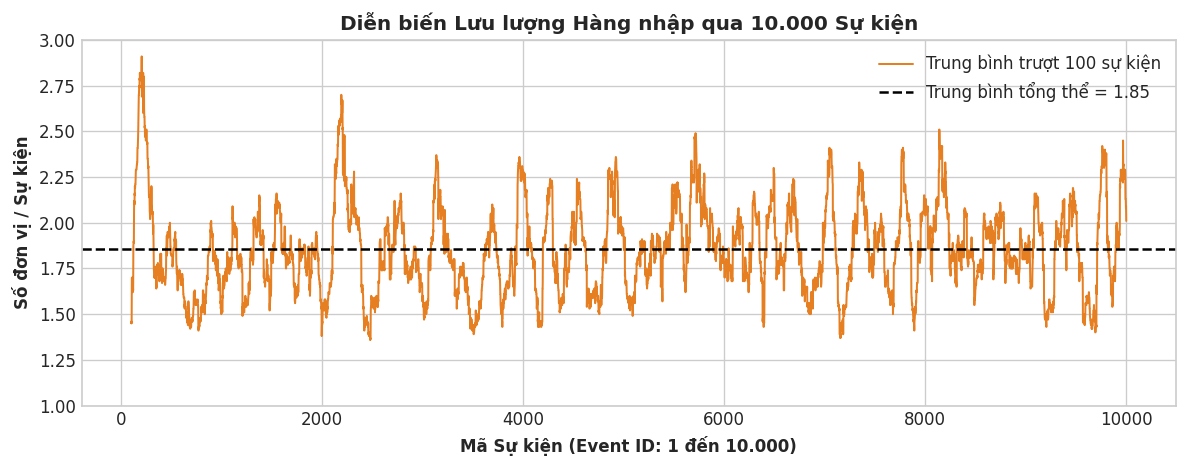

In [6]:
rolling_units = df_events['quantity'].rolling(window=100).mean()

plt.figure(figsize=(10, 4))
plt.plot(df_events['event_id'], rolling_units, color='#E67E22', linewidth=1.2, label='Trung bình trượt 100 sự kiện')
plt.axhline(df_events['quantity'].mean(), color='black', linestyle='--', label=f"Trung bình tổng thể = {df_events['quantity'].mean():.2f}")

plt.xlabel('Mã Sự kiện (Event ID: 1 đến 10.000)', fontweight='bold')
plt.ylabel('Số đơn vị / Sự kiện', fontweight='bold')
plt.title('Diễn biến Lưu lượng Hàng nhập qua 10.000 Sự kiện', fontweight='bold')
plt.ylim(1.0, 3.0)
plt.legend()
plt.tight_layout()
plt.show()
